## ILThermoPy Cookbook

> **Data snapshot — 16 October 2026**  
> This cookbook accompanies ILThermoPy **1.1.3** and its compound/SMILES data
> updated on 16 October 2026 (ILThermo 2.0 reports its last database update as
> **22 July 2026**). ILThermo is a live service: subsequent database updates
> may change **property keys, compound and entry IDs, search results, row counts,
> and individual values** for the same requests. The outputs illustrate the
> workflow; rerun the cells to obtain current results and check the database
> status with `ilt.CheckLastUpdate()`.


ILThermo 2.0 is a curated NIST database of experimental physicochemical
properties of ionic liquids and related systems. This cookbook demonstrates
accessing its records with the ILThermoPy Python package.


### Basic search

ILThermo 2.0 supports searches by compound name, CAS registry number or
chemical formula, the number of components, measured property, and publication
metadata. See the arguments of `ilt.Search` for details:


In [1]:
import ilthermopy as ilt

help(ilt.Search)

Help on function Search in module ilthermopy.search:

Search(compound: Optional[str] = None, n_compounds: Literal[None, 1, 2, 3] = None, prop: Optional[str] = None, prop_key: Optional[str] = None, year: Optional[int] = None, author: Optional[str] = None, keywords: Optional[str] = None) -> pandas.core.frame.DataFrame
    Runs ILThermo search and returns results as a dataframe
    
    Arguments:
        compound: chemical formula, CAS registry number, or name (part or full)
        n_compounds: number of mixture compounds
        prop: name of physico-chemical property, only used if prop_key is not specified
        prop_key: key of physico-chemical property (view available via GetPropertyList)
        year: publication year
        author: author's last name
        keywords: keywords presumably specified in paper's title
    
    Returns:
        dataframe containing main info on found entries



In [2]:
# search individual compounds published in 2004
df = ilt.Search(n_compounds = 1, year = 2004)
df

,id,reference,property,phases,num_phases,num_components,num_data_points,cmp1,cmp1_id,cmp1_smiles,cmp2,cmp2_id,cmp2_smiles,cmp3,cmp3_id,cmp3_smiles
0,vffQK,Kabo et al. (2004),Heat capacity at constant pressure,Liquid,1,1,1528,1-butyl-3-methylimidazolium hexafluorophosphate,ABChJv,CCCC[n+]1ccn(C)c1.F[P-](F)(F)(F)(F)F,None,None,None,None,None,None
1,aNLkc,Kabo et al. (2004),Heat capacity at vapor saturation pressure,Crystal;Gas,2,1,137,1-butyl-3-methylimidazolium hexafluorophosphate,ABChJv,CCCC[n+]1ccn(C)c1.F[P-](F)(F)(F)(F)F,None,None,None,None,None,None
2,bNHLG,Kabo et al. (2004),Heat capacity at vapor saturation pressure,Glass;Gas,2,1,111,1-butyl-3-methylimidazolium hexafluorophosphate,ABChJv,CCCC[n+]1ccn(C)c1.F[P-](F)(F)(F)(F)F,None,None,None,None,None,None
3,HzjQF,Sun et al. (2004),Heat capacity at constant pressure,Crystal,1,1,111,"4,6-dimethyl-N-phenylpyrimidin-2-amine dodecan...",ABYrQW,CCCCCCCCCCCC(=O)[O-].Cc1cc(C)nc(Nc2ccccc2)[nH+]1,None,None,None,None,None,None
4,sBpKf,Kabo et al. (2004),Heat capacity at vapor saturation pressure,Liquid;Gas,2,1,42,1-butyl-3-methylimidazolium hexafluorophosphate,ABChJv,CCCC[n+]1ccn(C)c1.F[P-](F)(F)(F)(F)F,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
272,CymfL,Zhao et al. (2004b),Viscosity,Liquid,1,1,1,1-(4-cyanobutyl)-3-methylimidazolium tetrafluo...,AAwOgS,Cn1cc[n+](CCCCC#N)c1.F[B-](F)(F)F,None,None,None,None,None,None
273,onFYh,Zhao et al. (2004b),Density,Liquid,1,1,1,1-butyl-3-methylimidazolium hexafluorophosphate,ABChJv,CCCC[n+]1ccn(C)c1.F[P-](F)(F)(F)(F)F,None,None,None,None,None,None
274,NaZFE,Zhao et al. (2004b),Viscosity,Liquid,1,1,1,1-butyl-3-methylimidazolium hexafluorophosphate,ABChJv,CCCC[n+]1ccn(C)c1.F[P-](F)(F)(F)(F)F,None,None,None,None,None,None
275,YbIco,Zhao et al. (2004b),Density,Liquid,1,1,1,1-butyl-3-methylimidazolium tetrafluoroborate,AArYBF,CCCC[n+]1ccn(C)c1.F[B-](F)(F)F,None,None,None,None,None,None


The result is a pandas DataFrame with one row per experimental data entry:

- **id**: ILThermo data-entry identifier, used by `ilt.GetEntry()`;
- **reference**: short citation of the source publication;
- **property**, **phases**: measured property and phases;
- **num_phases**, **num_components**, **num_data_points**: counts for the entry;
- **cmp1**, **cmp1_id**, **cmp1_smiles** (and similarly for components 2 and 3):
  the compound name, ILThermo compound identifier, and stored SMILES.


### Properties

You can search by a property name or its internal ILThermo key. The names
and keys available in the current database can be inspected with
`ilt.ShowPropertyList()`:


In [3]:
ilt.ShowPropertyList()


# Activity, fugacity, and osmotic properties
OeGx: Activity
IzuI: Mean ionic activity coefficient of component
ATdF: Osmotic coefficient

# Composition at phase equilibrium
xcJP: Composition at phase equilibrium
XSWH: Eutectic composition
lwkH: Henry's Law constant
AqYC: Tieline
aEcx: Upper consolute composition

# Critical properties
lsOT: Critical pressure
WuhL: Critical temperature
xUze: Upper consolute pressure
NMMC: Upper consolute temperature

# Excess, partial, and apparent energetic properties
TtDG: Apparent enthalpy
aJDm: Apparent isobaric molar heat capacity
mcIy: Enthalpy of dilution per amount of solute
aREM: Enthalpy of mixing of a binary solvent with component
iQPY: Excess enthalpy
iOPb: Integral enthalpy of solution
TMtf: Partial molar enthalpy

# Heat capacity and derived properties
KfbC: Enthalpy
jFrV: Enthalpy function {H(T)-H(0)}/T
LoTK: Entropy
Qneg: Heat capacity at constant pressure
MuWM: Heat capacity at constant volume
FXxs: Heat capacity at vapor saturation pr

The property names and internal keys can change between ILThermo database
versions. The `prop` argument of `ilt.Search()` resolves the name against the
current property list, while `prop_key` passes a specific internal key.
Prefer `prop` unless you explicitly need the key. An unknown property name
raises `ValueError`.


For programmatic access to the current names and keys, use
`ilt.PropertyList()`:


In [4]:
plist = ilt.PropertyList()
help(plist)

Help on PropertyList in module ilthermopy.data_structs object:

class PropertyList(builtins.object)
 |  Contains info on available physico-chemical properties and their API keys
 |  
 |  Attributes:
 |      properties (dict): two-level organized dictionary, interconnecting property
 |          types, properties, and their API keys
 |      key2prop (dict): maps API keys to property names
 |      prop2key (dict): maps property names to their API keys
 |  
 |  Methods defined here:
 |  
 |  Show(self) -> None
 |      Prints list of properties available in ILThermo 2.0 database
 |      formatted as api_key: property_name
 |  
 |  __init__(self)
 |      Initialize self.  See help(type(self)) for accurate signature.
 |  
 |  ----------------------------------------------------------------------
 |  Data descriptors defined here:
 |  
 |  __dict__
 |      dictionary for instance variables (if defined)
 |  
 |  __weakref__
 |      list of weak references to the object (if defined)



In [5]:
prop_name = 'Activity'
prop_key = plist.prop2key.get(prop_name, None)
print(prop_key)

OeGx


However, in most cases you do not need this functionality since the `ilt.Search` function supports the `prop` argument.

### Retrieving data

To retrieve the full experimental measurements for a search result, pass
its entry identifier to `ilt.GetEntry()`:


In [6]:
# Find entries for two-component systems published in 2004
df = ilt.Search(n_compounds=2, year=2004)
# Retrieve the first result (one API request)
entry = ilt.GetEntry(df['id'].iloc[0])
entry


Entry(id='srPOo', ref=Reference(full='Rebelo, L. P. N.; Najdanovic-Visak, V.; Visak, Z. P.; Nunes da Ponte, M.; Szydlowski, J.; Cerdeirina, C. A.; Troncoso, J.; Romani, L.; Esperanca, J. M. S. S.; Guedes, H. J. R.; de Sousa, H. C. (2004) Green Chem. 6(8), 369-381.'), property='Excess volume', property_type='Volumetric properties', phases=['Liquid'], components=[Compound(id='AADYJk', name='water', smiles='O'), Compound(id='AArYBF', name='1-butyl-3-methylimidazolium tetrafluoroborate', smiles='CCCC[n+]1ccn(C)c1.F[B-](F)(F)F')], num_data_points=185)

Entry object contains detailed information on the data entry, including:

- **id**: data entry ID;
- **ref**: reference to the source article;
- **property**, **property_type**: measured property and its type;
- **phases**: list of system's phases;
- **components**: list of system's components;
- **num_phases**, **num_components**, **num_data_points**: number of system's components and phases, and number of measured data points; 
- **expmeth**: experimental method used to obtain the physchemical data;
- **solvent**: solvent used in the experiment;
- **constraints**: list of experimental constraints;
- **data**: dataframe containing measured data;
- **header**: full column names to the **data**, containing info on the measured property, measurement units, component, and phase;
- **footnotes**: notes to the **data**;
- **response**: original response.

Let's illustrate the main attributes. Reference contains reference itself and the article's title:

In [7]:
entry.ref.full, entry.ref.title

('Rebelo, L. P. N.; Najdanovic-Visak, V.; Visak, Z. P.; Nunes da Ponte, M.; Szydlowski, J.; Cerdeirina, C. A.; Troncoso, J.; Romani, L.; Esperanca, J. M. S. S.; Guedes, H. J. R.; de Sousa, H. C. (2004) Green Chem. 6(8), 369-381.',
 'A detailed thermodynamic analysis of [C4mim][BF4] + water as a case study to model ionic liquid aqueous solutions')

Each component is a Compound object and contains the following fields:

- **id**: compound id;
- **name**: compound name;
- **formula**: chemical formula;
- **smiles**: compound SMILES;
- **smiles_error**: if compounds SMILES was not retrieved, this field describes the reason;
- **sample**: dictionary containing info on compound's source, purity, etc.;
- **mw**: molar weight of the compound, g/mol.

In [8]:
cmp1 = entry.components[0]
cmp1.id, cmp1.name, cmp1.formula, cmp1.smiles, cmp1.smiles_error, cmp1.sample, cmp1.mw

('AADYJk',
 'water',
 'H2 O',
 'O',
 None,
 {'Source': 'commercial source',
  'Purification': 'estimated by the compiler',
  'Purity': '99.8 mass %(fractional distillation)'},
 18.02)

The **data** attribute is a DataFrame containing the measured quantities.
Its columns have short labels (`V1`, `V2`, ...); when a measurement
uncertainty is present, the corresponding column uses a `d` prefix
(e.g. `V4` and `dV4`):


In [9]:
entry.data

,V1,V2,V3,V4,dV4
0,100.0,0.0040,278.15,-3.600000e-08,1.000000e-08
1,100.0,0.0040,283.15,-3.350000e-08,1.000000e-08
2,100.0,0.0040,288.15,-3.070000e-08,1.000000e-08
3,100.0,0.0040,293.15,-2.830000e-08,1.000000e-08
4,100.0,0.0040,298.15,-2.580000e-08,1.000000e-08
...,...,...,...,...,...
180,60000.0,0.5905,298.15,4.620000e-07,1.100000e-08
181,60000.0,0.5905,303.15,4.550000e-07,1.100000e-08
182,60000.0,0.5905,313.15,4.510000e-07,1.100000e-08
183,60000.0,0.5905,323.15,5.420000e-07,1.200000e-08


**header** field contains full names of the corresponding columns, including measured property, its measurement unit, and optionally compound and phase:

In [10]:
entry.header

{'V1': 'Pressure, kPa',
 'V2': 'Mole fraction of 1-butyl-3-methylimidazolium tetrafluoroborate => Liquid',
 'V3': 'Temperature, K',
 'V4': 'Excess volume, m<SUP>3</SUP>/mol => Liquid',
 'dV4': 'Error of excess volume, m<SUP>3</SUP>/mol => Liquid'}

Combining entries from different experiments may require harmonizing
variables, units, compositions, and constraints. This example focuses on
retrieving and inspecting the original records.


### Substructure search

#### Update status

ILThermoPy ships a table relating ILThermo compound identifiers and names
to curated SMILES strings. It looks up structures by ID first, with a name-based
fallback. Because ILThermo updates may reassign compound identifiers or alter
names, it is useful to check that the local structure snapshot corresponds to
the live database. The next cell runs that check:


In [11]:
ilt.CheckLastUpdate()

ILThermo 2.0 database was last updated on July 22, 2026
ilthermopy package was last updated on October 16, 2026

ilthermopy package is up-to-date


#### Substructure search

For an example, find compounds containing a **positively charged
guanidinium-like N–C(N)–N motif**. This includes N-substituted derivatives,
not just the unsubstituted guanidinium ion. First retrieve a table of
available experimental entries:


In [12]:
df = ilt.GetAllEntries()
df

,id,reference,property,phases,num_phases,num_components,num_data_points,cmp1,cmp1_id,cmp1_smiles,cmp2,cmp2_id,cmp2_smiles,cmp3,cmp3_id,cmp3_smiles
0,vffQK,Kabo et al. (2004),Heat capacity at constant pressure,Liquid,1,1,1528,1-butyl-3-methylimidazolium hexafluorophosphate,ABChJv,CCCC[n+]1ccn(C)c1.F[P-](F)(F)(F)(F)F,None,None,None,None,None,None
1,cFdQS,Strechan et al. (2008a),Heat capacity at vapor saturation pressure,Crystal 2;Gas,2,1,613,1-butyl-3-methylimidazolium trifluoroacetate,AAwaEi,CCCC[n+]1ccn(C)c1.O=C([O-])C(F)(F)F,None,None,None,None,None,None
2,eOKLZ,Safarov et al. (2021b),Viscosity,Liquid,1,1,500,1-ethyl-3-methylimidazolium dicyanamide,AAiEIE,CC[n+]1ccn(C)c1.N#C[N-]C#N,None,None,None,None,None,None
3,UkHsx,Polikhronidi et al. (2014),Heat capacity at constant pressure,Liquid,1,1,422,1-hexyl-3-methylimidazolium bis[(trifluorometh...,ABiCtA,CCCCCC[n+]1ccn(C)c1.O=S(=O)([N-]S(=O)(=O)C(F)(...,None,None,None,None,None,None
4,BvazU,Safarov et al. (2018c),Viscosity,Liquid,1,1,394,1-octyl-3-methylimidazolium hexafluorophosphate,ABNWoR,CCCCCCCC[n+]1ccn(C)c1.F[P-](F)(F)(F)(F)F,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54204,kxodn,Zhao et al. (2010a),Composition at phase equilibrium,Liquid;Gas,2,3,1,carbon dioxide,AAIYzl,O=C=O,water,AADYJk,O,2-hydroxy-N-(2-hydroxyethyl)-N-methylethanamin...,AAdwMT,C[NH+](CCO)CCO.[Cl-]
54205,WDULW,Zhao et al. (2010a),Composition at phase equilibrium,Liquid;Gas,2,3,1,carbon dioxide,AAIYzl,O=C=O,water,AADYJk,O,2-hydroxy-N-(2-hydroxyethyl)-N-methylethanamin...,AAnpCD,C[NH+](CCO)CCO.F[B-](F)(F)F
54206,trauR,Zhao et al. (2010a),Composition at phase equilibrium,Liquid;Gas,2,3,1,carbon dioxide,AAIYzl,O=C=O,water,AADYJk,O,2-hydroxyethanaminium tetrafluoroborate,AAcgPC,F[B-](F)(F)F.[NH3+]CCO
54207,YtOdr,Zhao et al. (2010a),Composition at phase equilibrium,Liquid;Gas,2,3,1,carbon dioxide,AAIYzl,O=C=O,water,AADYJk,O,1-butyl-3-methylimidazolium tetrafluoroborate,AArYBF,CCCC[n+]1ccn(C)c1.F[B-](F)(F)F


Next we get pre-stored list of all ILThermo compounds:

In [13]:
cmps = ilt.GetSavedCompounds().data
cmps

,id,name,smiles
0,AAAUNw,hydrogen (normal),[HH]
1,AAAoxC,helium,[He]
2,AADEqZ,methane,C
3,AADOHa,ammonia,N
4,AADYzl,water,O
...,...,...,...
3757,AGItKJ,"hexane-1,6-diylbis(trioctylphosphonium) docusate",S(=O)(=O)([O-])C(C(=O)OCC(CCCC)CC)CC(=O)OCC(CC...
3758,AGTiTJ,"decane-1,10-diylbis(trioctylphosphonium) docusate",S(=O)(=O)([O-])C(C(=O)OCC(CCCC)CC)CC(=O)OCC(CC...
3759,AGbVrp,"1,1'-(ethane-1,2-diyl)bis(3-(3-((3,3,4,4,5,5,6...",FC(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F...
3760,AGmPfb,tris(trihexyltetradecylphosphonium) hexachloro...,CCCCCCCCCCCCCC[P+](CCCCCC)(CCCCCC)CCCCCC.CCCCC...


Use RDKit to identify the compounds containing that substructure. The
SMARTS pattern below matches the charged nitrogen attached to a carbon
bonded to three nitrogens; it is intentionally broad and may include related
cationic amidines:


In [14]:
from rdkit import Chem

mols = [Chem.MolFromSmiles(smi) for smi in cmps.smiles]
pat = Chem.MolFromSmarts('[N+]~[CX3](~N)~N')
matches = [mol is not None and mol.HasSubstructMatch(pat) for mol in mols]
cmps = cmps.loc[matches]
cmps


,id,name,smiles
689,AAfsny,"N,N-dimethylimidodicarbonimidic diamide hydrochloride",CN(C)C(=[NH2+])NC(=N)N.[Cl-]
1749,ABDfwu,(2-ethoxyethyl)pentamethylguanidinium tetrafluoroborate,F[B-](F)(F)F.C(C)OCCN(C(N(C)C)=[N+](C)C)C
1789,ABEgAX,dibutyltetramethylguanidinium dicyanamide,CCCC[N+](CCCC)=C(N(C)C)N(C)C.N#C[N-]C#N
1792,ABEnPU,"5,7-dimethyl-1,5,7-triazabicyclo[4.4.0]dec-5-en-5-ium iodide",[I-].C[N+]=1CCCN2CCCN(C12)C
1815,ABFKhd,N-(bis(dimethylamino)methylene)-N-ethylethanaminium ethyl sulfate,S(=O)(=O)(OCC)[O-].CN(C)C(=[N+](CC)CC)N(C)C
...,...,...,...
3398,ACIAUR,(2-ethoxyethyl)pentamethylguanidinium bis(pentafluoroethylsulfonyl)amide,FC(C(F)(F)F)(S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F)F.C(C)OCCN(C(N(C)C)=[N+](C)C)C
3538,ACWOjJ,dimethyl di-octadecyl dimethylguanidinium chloride,[Cl-].CN(C(N(CCCCCCCCCCCCCCCCCC)C)=[N+](C)C)CCCCCCCCCCCCCCCCCC
3567,ACcIvq,dimethyl di-octadecyl dimethylguanidinium dicyanamide,CCCCCCCCCCCCCCCCCCN(C)C(N(C)CCCCCCCCCCCCCCCCCC)=[N+](C)C.N#C[N-]C#N
3655,ADHtyv,"diethyl bis(2,3-dibromo-2-methylpropyl) dimethylguanidinium bis(trifluoromethylsulfonyl)imide",[N-](S(=O)(=O)C(F)(F)F)S(=O)(=O)C(F)(F)F.C(C)N(C(N(CC(CBr)(Br)C)CC)=[N+](C)C)CC(CBr)(C)Br


Now select experimental entries involving at least one matching
compound. The exact entries depend on the current ILThermo database:


In [ ]:
sub = df.loc[
    df.cmp1_id.isin(cmps.id)
    | df.cmp2_id.isin(cmps.id)
    | df.cmp3_id.isin(cmps.id)
]
sub.head(10)


#### Resonance

Sometimes, substructure search will not work as expected unless resonance was considered. This can be demonstrated on non-symmetrical imidazolium cations:

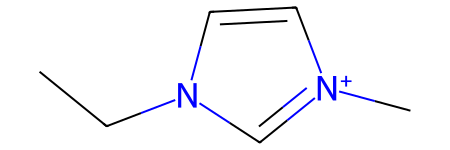

In [16]:
mol1 = Chem.MolFromSmiles('C[n+]1cc[n](CC)c1')
mol2 = Chem.MolFromSmiles('C[n]1cc[n+](CC)c1')
mol1

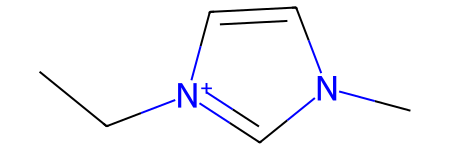

In [17]:
mol2

In [18]:
mol1.HasSubstructMatch(mol2)

False

These two SMILES encode equivalent resonance forms, but they are
represented as different molecular graphs. RDKit's default canonical SMILES
generation does not necessarily collapse such resonance representations:


In [19]:
Chem.MolToSmiles(mol1), Chem.MolToSmiles(mol2)

('CCn1cc[n+](C)c1', 'CC[n+]1ccn(C)c1')

There are two practical ways to make such searches less sensitive to
resonance representations:

1. Use more general SMARTS patterns, e.g. by avoiding a fixed charge or bond
   order when chemically appropriate (see the [Daylight SMARTS
   reference](https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html)).
2. Enumerate resonance structures with RDKit's `ResonanceMolSupplier` and
   compare the query against those alternatives.
